# Breast Cancer Classification Project

## 1. Introduction

In this project, we aim to build a Machine Learning model that can classify breast tumors as:

- Malignant (cancerous)
- Benign (non-cancerous)

This is a binary classification problem.

We will:
- Explore the dataset
- Split the data into training and testing sets
- Train multiple models
- Evaluate and compare their performance


In [4]:
import numpy as np
import pandas as pd

from sklearn.datasets import load_breast_cancer

# Load dataset
data = load_breast_cancer()

# Features
X = pd.DataFrame(data.data, columns=data.feature_names)

# Target
y = pd.Series(data.target, name="target")

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)
print("\nFirst 5 rows:")
display(X.head())


Shape of X: (569, 30)
Shape of y: (569,)

First 5 rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## Dataset Overview

The dataset contains 569 samples with 30 numerical features extracted from breast mass images.

Each sample is labeled as:
- 0: Malignant (cancerous)
- 1: Benign (non-cancerous)

This is a binary classification problem.

The dataset is available in the scikit-learn library (load_breast_cancer).



In [5]:
print("Target distribution:")
print(y.value_counts())

Target distribution:
target
1    357
0    212
Name: count, dtype: int64


## Class Distribution

The dataset shows a slight class imbalance:
- 357 benign cases
- 212 malignant cases

Since accuracy alone may be misleading in imbalanced datasets, we will also use precision, recall, and F1-score.


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)


Training set: (455, 30)
Testing set : (114, 30)


## Train-Test Split

The dataset was split into:
- 80% training data
- 20% testing data

We used stratification to preserve the class distribution in both sets.


## Baseline Model: Logistic Regression

We first train a Logistic Regression model without feature scaling to establish a baseline performance.


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Create model
model = LogisticRegression(max_iter=10000)

# Train
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Accuracy
acc = accuracy_score(y_test, y_pred)

print("Accuracy:", acc)


Accuracy: 0.9649122807017544


In [8]:
from sklearn.metrics import confusion_matrix, classification_report

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))


Confusion Matrix:
 [[39  3]
 [ 1 71]]

Classification Report:

              precision    recall  f1-score   support

           0       0.97      0.93      0.95        42
           1       0.96      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



## Feature Scaling

Logistic Regression is sensitive to feature scale.
We apply StandardScaler to normalize all features before training.


In [9]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Create pipeline
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=10000))
])

# Train
pipeline.fit(X_train, y_train)

# Predict
y_pred_scaled = pipeline.predict(X_test)

# Evaluate
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred_scaled))


              precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



## Classification Report Interpretation (After Scaling)

After applying feature scaling, the model performance improved.

- Precision measures how many predicted positives are actually correct.
- Recall measures how many actual positives were correctly identified.
- F1-score is the harmonic mean of precision and recall.

For malignant cases (class 0):
- High recall indicates the model successfully detects most cancer cases.
- Low false negatives are critical in medical diagnosis.

For benign cases (class 1):
- High precision and recall indicate strong classification


## ROC Curve and AUC

We evaluate the model using the ROC curve and compute the AUC score.
ROC shows the trade-off between True Positive Rate (Recall) and False Positive Rate.
A higher AUC indicates better classification ability.


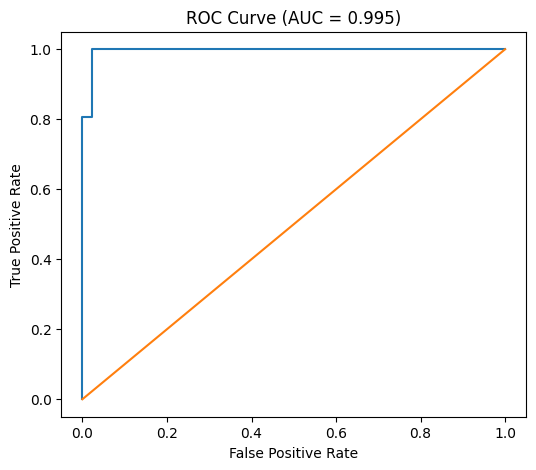

AUC Score: 0.9953703703703703


In [10]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Predicted probabilities for class 1 (Benign)
y_prob = pipeline.predict_proba(X_test)[:, 1]

# AUC Score
auc = roc_auc_score(y_test, y_prob)

# ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"ROC Curve (AUC = {auc:.3f})")
plt.show()

print("AUC Score:", auc)


### Interpretation

The ROC curve summarizes performance across all classification thresholds.
An AUC close to 1 indicates excellent ability to distinguish between malignant and benign cases.


## Confusion Matrix Visualization

To better understand model performance, we visualize the confusion matrix using a heatmap.
This helps interpret true positives, false positives, false negatives, and true negatives.


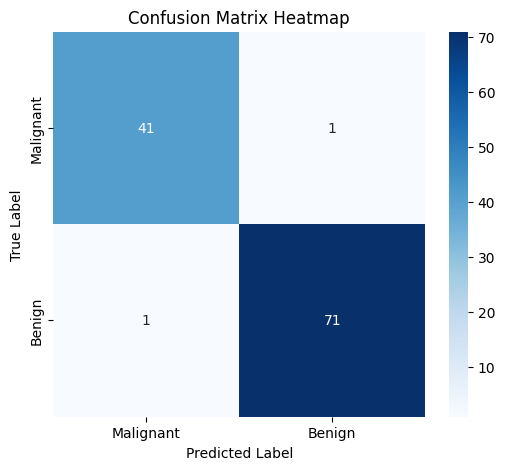

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Generate confusion matrix using scaled pipeline predictions
cm = confusion_matrix(y_test, y_pred_scaled)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Malignant', 'Benign'],
            yticklabels=['Malignant', 'Benign'])

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix Heatmap")
plt.show()


## Confusion Matrix Interpretation

The confusion matrix shows the distribution of correct and incorrect predictions.

- True Negatives (41): Malignant cases correctly classified.
- True Positives (71): Benign cases correctly classified.
- False Positives (1): Benign cases incorrectly classified as malignant.
- False Negatives (1): Malignant cases incorrectly classified as benign.

In medical diagnosis, minimizing false negatives is especially important because failing to detect a malignant case can have serious consequences.

The model shows very low false negatives (only 1 case), indicating strong diagnostic performance.


## Cross-Validation

To obtain a more robust estimate of performance, we use 5-fold cross-validation instead of relying on a single train-test split.


In [12]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(pipeline, X, y, cv=5)

print("Cross-validation scores:", cv_scores)
print("Mean CV accuracy:", cv_scores.mean())


Cross-validation scores: [0.98245614 0.98245614 0.97368421 0.97368421 0.99115044]
Mean CV accuracy: 0.9806862288464524


## Learning Curve Analysis

We analyze how model performance changes as the training size increases.

This helps determine whether the model would benefit from more data
and whether there is overfitting or underfitting.


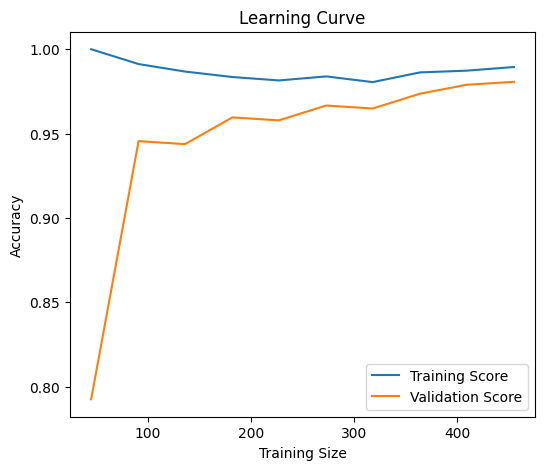

In [16]:
from sklearn.model_selection import learning_curve
import numpy as np
import matplotlib.pyplot as plt

train_sizes, train_scores, val_scores = learning_curve(
    pipeline, X, y, cv=5,
    train_sizes=np.linspace(0.1, 1.0, 10),
    scoring='accuracy'
)

train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)

plt.figure(figsize=(6,5))
plt.plot(train_sizes, train_mean, label="Training Score")
plt.plot(train_sizes, val_mean, label="Validation Score")
plt.xlabel("Training Size")
plt.ylabel("Accuracy")
plt.title("Learning Curve")
plt.legend()
plt.show()


### Learning Curve Interpretation

If training and validation curves are close and high,
the model generalizes well.

If there is a large gap, it may indicate overfitting.

The plot helps determine whether increasing dataset size
would significantly improve performance.


## PCA (Dimensionality Reduction)

We apply PCA to reduce dimensionality while keeping 95% of the variance.
This helps evaluate whether fewer components can maintain similar performance.


In [13]:
from sklearn.decomposition import PCA
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

pipeline_pca = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=0.95)),
    ('model', LogisticRegression(max_iter=10000))
])

scores_pca = cross_val_score(pipeline_pca, X, y, cv=5)

print("PCA CV scores:", scores_pca)
print("PCA Mean CV Accuracy:", scores_pca.mean())


PCA CV scores: [0.99122807 0.97368421 0.98245614 0.97368421 0.98230088]
PCA Mean CV Accuracy: 0.98067070330694


### PCA Analysis

If PCA achieves similar accuracy to the full-feature model, it suggests that many features are correlated
and dimensionality reduction does not significantly harm performance.


## Model Comparison

We compare Logistic Regression, KNN, and SVM using 5-fold cross-validation to determine the best-performing model.


In [14]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

models = {
    "Logistic Regression": LogisticRegression(max_iter=10000),
    "KNN": KNeighborsClassifier(),
    "SVM": SVC()
}

for name, model in models.items():
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('model', model)
    ])
    
    scores = cross_val_score(pipe, X, y, cv=5)
    print(f"{name} Mean CV Accuracy: {scores.mean():.4f}")


Logistic Regression Mean CV Accuracy: 0.9807
KNN Mean CV Accuracy: 0.9649
SVM Mean CV Accuracy: 0.9736


## Hyperparameter Tuning

We use GridSearchCV to tune the regularization parameter (C) of Logistic Regression and evaluate if performance improves.


In [15]:
from sklearn.model_selection import GridSearchCV

pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=10000))
])

param_grid = {
    'model__C': [0.01, 0.1, 1, 10, 100]
}

grid = GridSearchCV(pipe, param_grid, cv=5)
grid.fit(X, y)

print("Best C:", grid.best_params_)
print("Best CV score:", grid.best_score_)


Best C: {'model__C': 1}
Best CV score: 0.9806862288464524


## Conclusion

In this project, we built multiple classification models to predict whether a breast tumor is malignant or benign.

We compared Logistic Regression, KNN, and SVM using 5-fold cross-validation.

Logistic Regression achieved the highest average accuracy (~98%).

Hyperparameter tuning confirmed that the default regularization parameter (C=1) was already optimal.

The model shows high precision and recall, especially for malignant cases, which is critical in medical diagnosis.

Overall, Logistic Regression proved to be the most suitable model for this dataset.
